In [1]:
import sys
sys.path.append("..")

from src.data import cargar_datos, particionar
from src.metrics import riesgo_cuadratico

X, y = cargar_datos("../data/Datos_Hitters.csv")
print(X.shape, y.isna().sum())

X_tr, X_val, X_test, y_tr, y_val, y_test = particionar(X, y)
print(len(X_tr), len(X_val), len(X_test))

(263, 19) 0
50 70 143


In [2]:
import pandas as pd
pd.set_option("display.float_format", "{:.2f}".format)

## Ejercicio 1. Modelo completo

### (a) Riesgo en entrenamiento y validación

In [3]:
from sklearn.linear_model import LinearRegression

# Modelo con intercepto (fit_intercept=True es el valor por defecto, lo dejamos explícito)
modelo_completo = LinearRegression(fit_intercept=True)

# Se ajusta SOLO con entrenamiento
modelo_completo.fit(X_tr, y_tr)

# Predicciones en cada conjunto
pred_tr = modelo_completo.predict(X_tr)
pred_val = modelo_completo.predict(X_val)

# Riesgos con la función propia de src/metrics.py
riesgo_tr = riesgo_cuadratico(y_tr, pred_tr)
riesgo_val = riesgo_cuadratico(y_val, pred_val)

print(f"Riesgo de entrenamiento: {riesgo_tr:.2f}")
print(f"Riesgo de validación:    {riesgo_val:.2f}")

Riesgo de entrenamiento: 68584.82
Riesgo de validación:    320423.19


### (b) Registro de los valores

In [4]:
import pandas as pd

resultados = {}
resultados["Todas las variables"] = {
    "variables": list(X_tr.columns),
    "riesgo_train": riesgo_tr,
    "riesgo_val": riesgo_val,
}

pd.DataFrame({
    "Modelo": ["Todas las variables"],
    "N° variables": [X_tr.shape[1]],
    "Riesgo train": [riesgo_tr],
    "Riesgo validación": [riesgo_val],
})

,Modelo,N° variables,Riesgo train,Riesgo validación
0,Todas las variables,19,68584.82,320423.19


## Ejercicio 2. Selección estadística de variables

### (a) Correlación de Pearson con Salary

In [5]:
from src.modelos import ajustar_y_evaluar

# Correlación de cada variable con Salary, solo con entrenamiento
corr = X_tr.corrwith(y_tr)
corr_ordenada = corr.reindex(corr.abs().sort_values(ascending=False).index)

pd.DataFrame({
    "Correlación": corr_ordenada,
    "|Correlación|": corr_ordenada.abs(),
})

,Correlación,|Correlación|
CRBI,0.43,0.43
CRuns,0.43,0.43
CHmRun,0.42,0.42
CHits,0.42,0.42
CAtBat,0.38,0.38
CWalks,0.29,0.29
Years,0.24,0.24
PutOuts,0.19,0.19
HmRun,0.18,0.18
RBI,0.18,0.18


### (b) Regresión con las 7 variables de mayor correlación

In [6]:
vars_corr = corr_ordenada.index[:7].tolist()

modelo_corr, r_tr_corr, r_val_corr = ajustar_y_evaluar(vars_corr, X_tr, y_tr, X_val, y_val)

print("Variables:", vars_corr)
print(f"Riesgo de entrenamiento: {r_tr_corr:.2f}")
print(f"Riesgo de validación:    {r_val_corr:.2f}")

resultados["Mayor correlación"] = {
    "variables": vars_corr,
    "riesgo_train": r_tr_corr,
    "riesgo_val": r_val_corr,
}

Variables: ['CRBI', 'CRuns', 'CHmRun', 'CHits', 'CAtBat', 'CWalks', 'Years']
Riesgo de entrenamiento: 115487.25
Riesgo de validación:    133035.61


### (c) Selección por valor p de la prueba t

In [7]:
import statsmodels.api as sm

# Regresión completa con statsmodels (solo entrenamiento) para obtener los valores p
ols = sm.OLS(y_tr, sm.add_constant(X_tr)).fit()
pvalores = ols.pvalues.drop("const")   # el intercepto no es una variable

print(pvalores.sort_values().round(4))

vars_t = pvalores[pvalores < 0.05].index.tolist()
print("\nVariables con p < 0.05:", vars_t)

modelo_t, r_tr_t, r_val_t = ajustar_y_evaluar(vars_t, X_tr, y_tr, X_val, y_val)

print(f"Riesgo de entrenamiento: {r_tr_t:.2f}")
print(f"Riesgo de validación:    {r_val_t:.2f}")

resultados["Pruebas t"] = {
    "variables": vars_t,
    "riesgo_train": r_tr_t,
    "riesgo_val": r_val_t,
}

AtBat       0.00
Assists     0.01
CWalks      0.04
Runs        0.08
Errors      0.08
RBI         0.10
Years       0.20
CRuns       0.37
NewLeague   0.44
CHmRun      0.44
PutOuts     0.48
CAtBat      0.51
CHits       0.59
HmRun       0.73
League      0.77
Walks       0.77
CRBI        0.80
Hits        0.88
Division    1.00
dtype: float64

Variables con p < 0.05: ['AtBat', 'CWalks', 'Assists']
Riesgo de entrenamiento: 161221.36
Riesgo de validación:    140085.19


### (d) Variables seleccionadas y comparación de riesgos

In [8]:
for nombre in ["Mayor correlación", "Pruebas t"]:
    print(f"{nombre}: {resultados[nombre]['variables']}\n")

pd.DataFrame({
    "Modelo": list(resultados.keys()),
    "N° variables": [len(r["variables"]) for r in resultados.values()],
    "Riesgo train": [r["riesgo_train"] for r in resultados.values()],
    "Riesgo validación": [r["riesgo_val"] for r in resultados.values()],
})

Mayor correlación: ['CRBI', 'CRuns', 'CHmRun', 'CHits', 'CAtBat', 'CWalks', 'Years']

Pruebas t: ['AtBat', 'CWalks', 'Assists']



,Modelo,N° variables,Riesgo train,Riesgo validación
0,Todas las variables,19,68584.82,320423.19
1,Mayor correlación,7,115487.25,133035.61
2,Pruebas t,3,161221.36,140085.19


## Ejercicio 3. Selección hacia adelante

### (a) Tabla de pasos

In [9]:
from src.modelos import seleccion_adelante

pasos = seleccion_adelante(X_tr, y_tr, X_val, y_val)

tabla_adelante = pd.DataFrame(pasos).drop(columns="variables")
tabla_adelante

,N° variables,Variable agregada,Riesgo train,Riesgo validación
0,1,CRBI,144809.32,146285.39
1,2,Years,131715.69,142801.71
2,3,CRuns,126982.32,130618.20
3,4,AtBat,123026.44,148610.24
4,5,Hits,113273.76,134668.75
5,6,CWalks,104271.87,162725.89
6,7,RBI,97143.24,196523.65
7,8,Assists,92928.74,188600.44
8,9,Errors,87364.02,211733.49
9,10,Runs,80524.82,271303.13


### (b) Gráfica de los riesgos

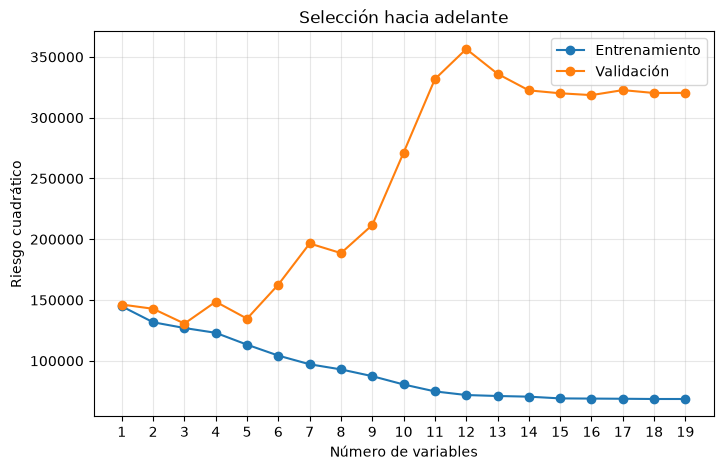

In [10]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.plot(tabla_adelante["N° variables"], tabla_adelante["Riesgo train"], marker="o", label="Entrenamiento")
plt.plot(tabla_adelante["N° variables"], tabla_adelante["Riesgo validación"], marker="o", label="Validación")
plt.xlabel("Número de variables")
plt.ylabel("Riesgo cuadrático")
plt.title("Selección hacia adelante")
plt.xticks(range(1, 20))
plt.legend()
plt.grid(alpha=0.3)
plt.show()

### (c) Modelo con menor riesgo de validación

In [11]:
i_mejor = tabla_adelante["Riesgo validación"].idxmin()
vars_adelante = pasos[i_mejor]["variables"]

print("N° de variables:", len(vars_adelante))
print("Variables:", vars_adelante)
print(f"Riesgo de entrenamiento: {pasos[i_mejor]['Riesgo train']:.2f}")
print(f"Riesgo de validación:    {pasos[i_mejor]['Riesgo validación']:.2f}")

resultados["Selección hacia adelante"] = {
    "variables": vars_adelante,
    "riesgo_train": pasos[i_mejor]["Riesgo train"],
    "riesgo_val": pasos[i_mejor]["Riesgo validación"],
}

N° de variables: 3
Variables: ['CRBI', 'Years', 'CRuns']
Riesgo de entrenamiento: 126982.32
Riesgo de validación:    130618.20


**Respuesta:** el modelo con menor riesgo de validación es el de **3 variables**, con riesgo de validación **130618.20** (y de entrenamiento 126982.32). Las variables que utiliza son:

- **CRBI**
- **Years**
- **CRuns**

A partir de la cuarta variable el riesgo de entrenamiento sigue bajando, pero el de validación sube (con 4 variables ya es 148610.24), lo que indica sobreajuste.

## Ejercicio 4. Comparación final

### (a) Modelo elegido con validación

In [12]:
elegido = min(resultados, key=lambda k: resultados[k]["riesgo_val"])

print("Modelo elegido:", elegido)
print(f"Riesgo de validación: {resultados[elegido]['riesgo_val']:.2f}")

Modelo elegido: Selección hacia adelante
Riesgo de validación: 130618.20


**Respuesta (a):** el modelo elegido con base en validación es **Selección hacia adelante** (CRBI, Years y CRuns), porque tiene el menor riesgo de validación de los cuatro: **130618.20**. Le siguen Mayor correlación (133035.61), Pruebas t (140085.19) y Todas las variables (320423.19).

### (b) Tabla comparativa

In [13]:
filas = []
for nombre, datos in resultados.items():
    vs = datos["variables"]
    modelo, _, _ = ajustar_y_evaluar(vs, X_tr, y_tr, X_val, y_val)   # ajustado solo con entrenamiento
    datos["riesgo_test"] = riesgo_cuadratico(y_test, modelo.predict(X_test[vs]))
    filas.append({
        "Modelo": nombre,
        "Variables": "Las 19" if len(vs) == 19 else ", ".join(vs),
        "Riesgo train": datos["riesgo_train"],
        "Riesgo validación": datos["riesgo_val"],
        "Riesgo prueba": datos["riesgo_test"],
    })

tabla_final = pd.DataFrame(filas)
tabla_final

,Modelo,Variables,Riesgo train,Riesgo validación,Riesgo prueba
0,Todas las variables,Las 19,68584.82,320423.19,394308.69
1,Mayor correlación,"CRBI, CRuns, CHmRun, CHits, CAtBat, CWalks, Years",115487.25,133035.61,145923.29
2,Pruebas t,"AtBat, CWalks, Assists",161221.36,140085.19,158772.47
3,Selección hacia adelante,"CRBI, Years, CRuns",126982.32,130618.20,126939.60


### (c) Menor riesgo de entrenamiento y menor riesgo de prueba

In [14]:
print("Menor riesgo de entrenamiento:", min(resultados, key=lambda k: resultados[k]["riesgo_train"]))
print("Menor riesgo de prueba:       ", min(resultados, key=lambda k: resultados[k]["riesgo_test"]))

Menor riesgo de entrenamiento: Todas las variables
Menor riesgo de prueba:        Selección hacia adelante


**Respuesta (c):** el menor riesgo de entrenamiento es el de **Todas las variables** (68584.82), y el menor riesgo de prueba es el de **Selección hacia adelante** (126939.60). **No coinciden.** El modelo con todas las variables es el que mejor se ajusta a los 50 jugadores de entrenamiento, pero es el peor en prueba (394308.69): memorizó los datos de entrenamiento y no generaliza.

### (d) ¿El modelo elegido con validación fue el de menor riesgo de prueba?

**Respuesta (d):** **Sí.** El modelo elegido con validación fue Selección hacia adelante (riesgo de validación 130618.20), y también es el de menor riesgo de prueba: **126939.60**, frente a 145923.29 de Mayor correlación, 158772.47 de Pruebas t y 394308.69 de Todas las variables. Además, su riesgo de prueba es muy cercano al de validación, lo que indica que la elección en validación fue confiable.